# NHS Referral-to-Treatment Waiting Times Analysis
## Exploratory Data Analysis

**Analysis window:** April 2025 to July 2026  
**Dataset:** NHS England Consultant-led Referral to Treatment (RTT) — Incomplete Provider data

### Objectives

This notebook answers:

1. How has the overall waiting list changed?
2. Is 18-week performance improving or deteriorating?
3. How are 52+, 65+ and 78+ week waits changing?
4. Which providers face the greatest pressure?
5. Which specialties contribute most to pressure?
6. How is Gloucestershire Hospitals NHS Foundation Trust performing over time?

> Run `03_multi_month_data_preparation.ipynb` first. This notebook expects the combined clean CSV outputs from that stage.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")


## Load the processed trend datasets

In [2]:
processed_dir = Path("../data/processed")

full_file = processed_dir / "rtt_incomplete_provider_apr2025_jul2026_clean.csv"
provider_file = processed_dir / "rtt_provider_totals_apr2025_jul2026.csv"

missing = [p.name for p in [full_file, provider_file] if not p.exists()]

if missing:
    raise FileNotFoundError(
        "Missing processed trend dataset(s): "
        + ", ".join(missing)
        + ". Run 03_multi_month_data_preparation.ipynb first."
    )

full_df = pd.read_csv(full_file, parse_dates=["reporting_month"])
provider_df = pd.read_csv(provider_file, parse_dates=["reporting_month"])

print("Full dataset:", full_df.shape)
print("Provider totals:", provider_df.shape)


Full dataset: (57480, 125)
Provider totals: (2395, 125)


## Confirm coverage and uniqueness

In [3]:
coverage = (
    provider_df
    .groupby(["reporting_month", "reporting_period"], as_index=False)
    .agg(
        providers=("provider_code", "nunique"),
        rows=("provider_code", "size")
    )
)

coverage


,reporting_month,reporting_period,providers,rows
0,2025-04-01,2025-04,152,152
1,2025-05-01,2025-05,152,152
2,2025-06-01,2025-06,152,152
3,2025-07-01,2025-07,150,150
4,2025-08-01,2025-08,150,150
5,2025-09-01,2025-09,150,150
6,2025-10-01,2025-10,150,150
7,2025-11-01,2025-11,149,149
8,2025-12-01,2025-12,150,150
9,2026-01-01,2026-01,150,150


In [4]:
print(
    "Period:",
    provider_df["reporting_month"].min().strftime("%B %Y"),
    "to",
    provider_df["reporting_month"].max().strftime("%B %Y")
)

print("Months:", provider_df["reporting_month"].nunique())

duplicate_count = provider_df.duplicated(
    subset=["reporting_month", "provider_code"]
).sum()

print("Duplicate provider-month rows:", duplicate_count)
assert duplicate_count == 0


Period: April 2025 to July 2026
Months: 16
Duplicate provider-month rows: 0


Provider coverage can change over time because organisations may merge, split, enter or leave the reporting set. Interpret national trends alongside provider counts rather than assuming the reporting population is perfectly static.


# Part A — Overall waiting-list trends

## Create weighted monthly KPIs

In [5]:
national_monthly = (
    provider_df
    .groupby(["reporting_month", "reporting_period"], as_index=False)
    .agg(
        providers=("provider_code", "nunique"),
        total_waiting=("total_waiting", "sum"),
        within_18_weeks=("within_18_weeks", "sum"),
        over_18_weeks=("over_18_weeks", "sum"),
        over_52_weeks=("over_52_weeks", "sum"),
        over_65_weeks=("over_65_weeks", "sum"),
        over_78_weeks=("over_78_weeks", "sum"),
    )
    .sort_values("reporting_month")
)

national_monthly["pct_within_18_weeks"] = (
    national_monthly["within_18_weeks"]
    / national_monthly["total_waiting"]
    * 100
)

national_monthly["pct_over_18_weeks"] = (
    national_monthly["over_18_weeks"]
    / national_monthly["total_waiting"]
    * 100
)

for threshold in [52, 65, 78]:
    national_monthly[f"pct_over_{threshold}_weeks"] = (
        national_monthly[f"over_{threshold}_weeks"]
        / national_monthly["total_waiting"]
        * 100
    )

national_monthly


,reporting_month,reporting_period,providers,total_waiting,within_18_weeks,over_18_weeks,over_52_weeks,over_65_weeks,over_78_weeks,pct_within_18_weeks,pct_over_18_weeks,pct_over_52_weeks,pct_over_65_weeks,pct_over_78_weeks
0,2025-04-01,2025-04,152,6998951,4112155,2886796,186464,8019,701,58.75,41.25,2.66,0.11,0.01
1,2025-05-01,2025-05,152,6962631,4173533,2789098,193581,10469,769,59.94,40.06,2.78,0.15,0.01
2,2025-06-01,2025-06,152,6957979,4214112,2743867,188022,9421,666,60.57,39.43,2.70,0.14,0.01
3,2025-07-01,2025-07,150,6883308,4148781,2734527,184799,10572,857,60.27,39.73,2.68,0.15,0.01
4,2025-08-01,2025-08,150,6886287,4125841,2760446,184692,11713,988,59.91,40.09,2.68,0.17,0.01
5,2025-09-01,2025-09,150,6865336,4169234,2696102,174361,11624,1024,60.73,39.27,2.54,0.17,0.01
6,2025-10-01,2025-10,150,6865854,4168559,2697295,165909,11181,1246,60.71,39.29,2.42,0.16,0.02
7,2025-11-01,2025-11,149,6731987,4081670,2650317,151230,8581,1117,60.63,39.37,2.25,0.13,0.02
8,2025-12-01,2025-12,150,6767991,4094864,2673127,136058,6668,1217,60.50,39.50,2.01,0.10,0.02
9,2026-01-01,2026-01,150,6722905,4072488,2650417,130997,6799,1321,60.58,39.42,1.95,0.10,0.02


**Why weighted percentages?**  
Do not average provider percentages directly. The correct overall percentage is calculated from summed pathway counts so larger and smaller providers are weighted appropriately.


## Total waiting list over time

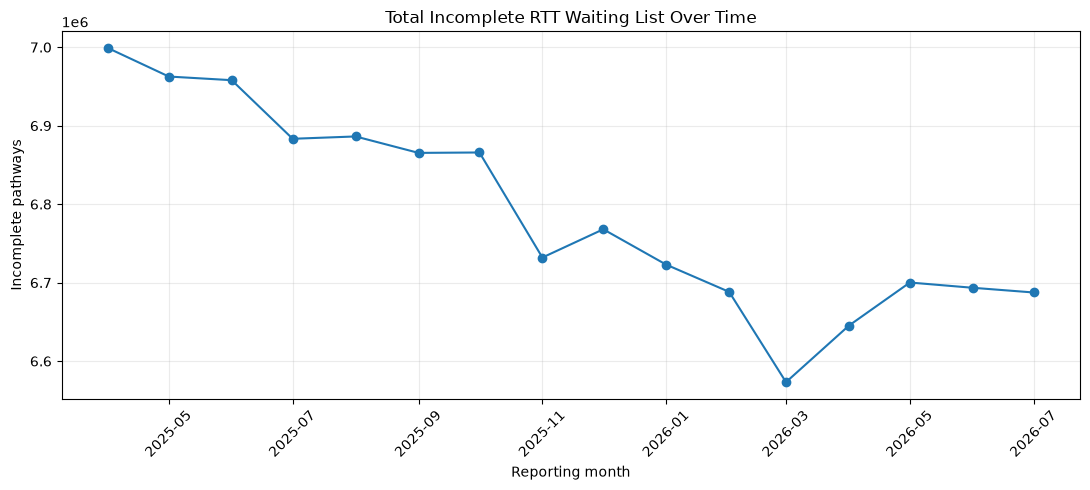

In [6]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    national_monthly["reporting_month"],
    national_monthly["total_waiting"],
    marker="o"
)

ax.set_title("Total Incomplete RTT Waiting List Over Time")
ax.set_xlabel("Reporting month")
ax.set_ylabel("Incomplete pathways")
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


In [7]:
first = national_monthly.iloc[0]
latest = national_monthly.iloc[-1]

waiting_change = latest["total_waiting"] - first["total_waiting"]
waiting_change_pct = waiting_change / first["total_waiting"] * 100

print(f"Start ({first['reporting_period']}): {first['total_waiting']:,.0f}")
print(f"Latest ({latest['reporting_period']}): {latest['total_waiting']:,.0f}")
print(f"Absolute change: {waiting_change:+,.0f}")
print(f"Percentage change: {waiting_change_pct:+.2f}%")


Start (2025-04): 6,998,951
Latest (2026-07): 6,687,433
Absolute change: -311,518
Percentage change: -4.45%


## Month-on-month waiting-list change

In [8]:
national_monthly["mom_waiting_change"] = national_monthly["total_waiting"].diff()
national_monthly["mom_waiting_change_pct"] = national_monthly["total_waiting"].pct_change() * 100

national_monthly[
    [
        "reporting_period",
        "total_waiting",
        "mom_waiting_change",
        "mom_waiting_change_pct"
    ]
]


,reporting_period,total_waiting,mom_waiting_change,mom_waiting_change_pct
0,2025-04,6998951,NaN,NaN
1,2025-05,6962631,"-36,320.00",-0.52
2,2025-06,6957979,"-4,652.00",-0.07
3,2025-07,6883308,"-74,671.00",-1.07
4,2025-08,6886287,"2,979.00",0.04
5,2025-09,6865336,"-20,951.00",-0.30
6,2025-10,6865854,518.00,0.01
7,2025-11,6731987,"-133,867.00",-1.95
8,2025-12,6767991,"36,004.00",0.53
9,2026-01,6722905,"-45,086.00",-0.67


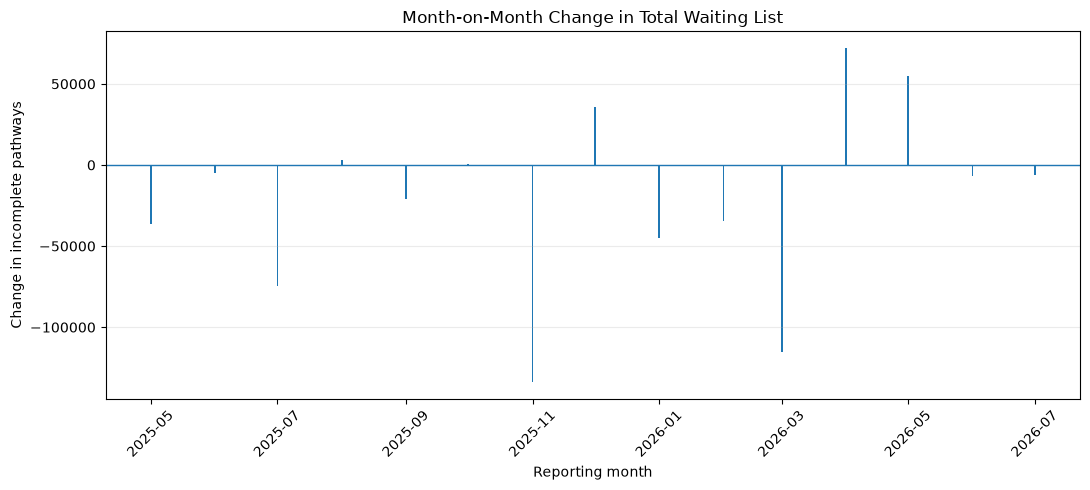

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    national_monthly["reporting_month"],
    national_monthly["mom_waiting_change"]
)

ax.axhline(0, linewidth=1)
ax.set_title("Month-on-Month Change in Total Waiting List")
ax.set_xlabel("Reporting month")
ax.set_ylabel("Change in incomplete pathways")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


# Part B — 18-week performance

## Weighted percentage within 18 weeks

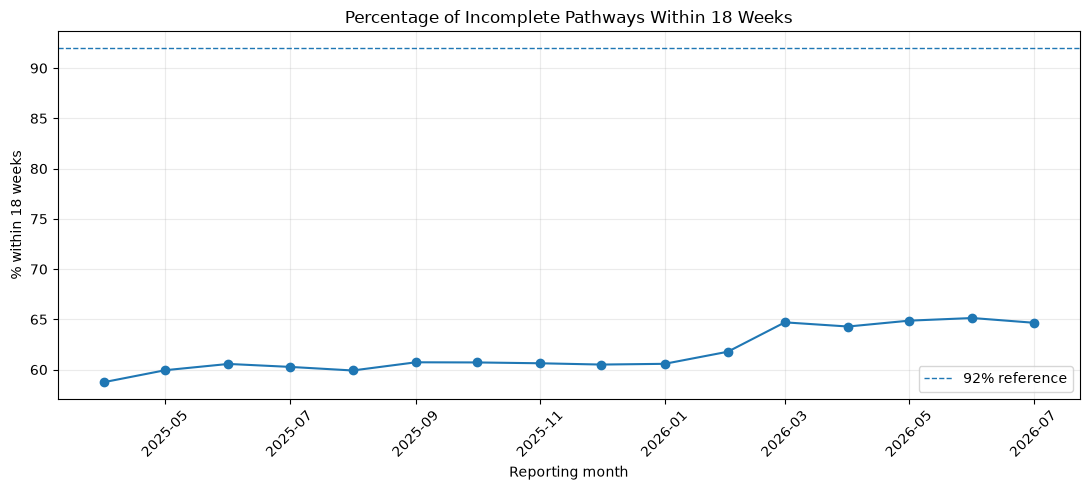

In [10]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    national_monthly["reporting_month"],
    national_monthly["pct_within_18_weeks"],
    marker="o"
)

ax.axhline(92, linestyle="--", linewidth=1, label="92% reference")
ax.set_title("Percentage of Incomplete Pathways Within 18 Weeks")
ax.set_xlabel("Reporting month")
ax.set_ylabel("% within 18 weeks")
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


In [11]:
performance_change_pp = (
    latest["pct_within_18_weeks"]
    - first["pct_within_18_weeks"]
)

print(f"Start: {first['pct_within_18_weeks']:.2f}%")
print(f"Latest: {latest['pct_within_18_weeks']:.2f}%")
print(f"Change: {performance_change_pp:+.2f} percentage points")


Start: 58.75%
Latest: 64.66%
Change: +5.91 percentage points


# Part C — Long-wait pressure

## 52+, 65+ and 78+ week trends

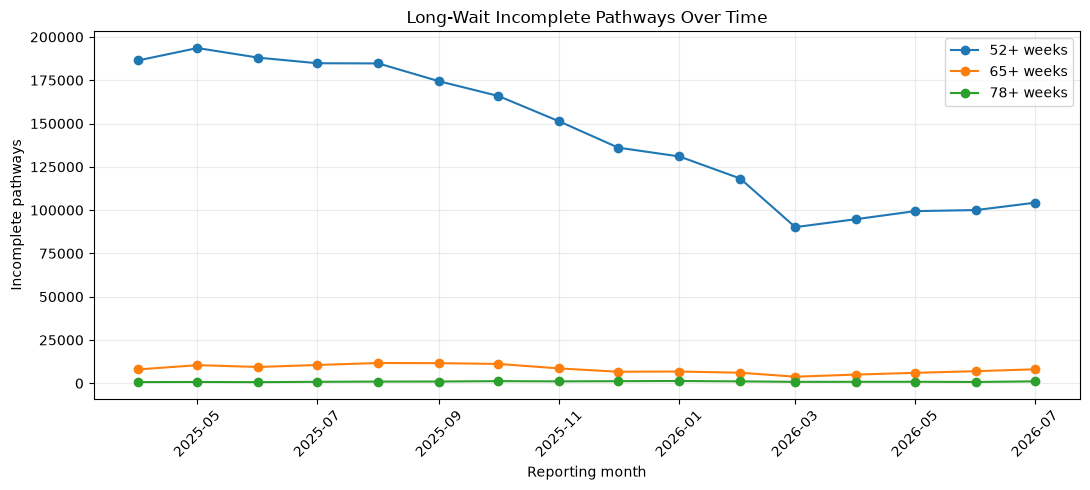

In [12]:
fig, ax = plt.subplots(figsize=(11, 5))

for column, label in [
    ("over_52_weeks", "52+ weeks"),
    ("over_65_weeks", "65+ weeks"),
    ("over_78_weeks", "78+ weeks"),
]:
    ax.plot(
        national_monthly["reporting_month"],
        national_monthly[column],
        marker="o",
        label=label
    )

ax.set_title("Long-Wait Incomplete Pathways Over Time")
ax.set_xlabel("Reporting month")
ax.set_ylabel("Incomplete pathways")
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


In [13]:
long_wait_change = pd.DataFrame({
    "measure": ["52+ weeks", "65+ weeks", "78+ weeks"],
    "start": [
        first["over_52_weeks"],
        first["over_65_weeks"],
        first["over_78_weeks"],
    ],
    "latest": [
        latest["over_52_weeks"],
        latest["over_65_weeks"],
        latest["over_78_weeks"],
    ]
})

long_wait_change["absolute_change"] = (
    long_wait_change["latest"] - long_wait_change["start"]
)

long_wait_change["pct_change"] = np.where(
    long_wait_change["start"] != 0,
    long_wait_change["absolute_change"] / long_wait_change["start"] * 100,
    np.nan
)

long_wait_change


,measure,start,latest,absolute_change,pct_change
0,52+ weeks,186464,104286,-82178,-44.07
1,65+ weeks,8019,8080,61,0.76
2,78+ weeks,701,1115,414,59.06


# Part D — Latest provider performance

## Latest reporting month

In [14]:
latest_month = provider_df["reporting_month"].max()

latest_providers = provider_df[
    provider_df["reporting_month"] == latest_month
].copy()

print("Latest month:", latest_month.strftime("%B %Y"))
print("Providers:", latest_providers["provider_code"].nunique())


Latest month: July 2026
Providers: 146


## Providers with the largest waiting lists

In [15]:
largest_waiting_lists = (
    latest_providers[
        [
            "provider_code",
            "provider_name",
            "total_waiting",
            "pct_within_18_weeks",
            "over_52_weeks",
            "median_wait_weeks",
            "p92_wait_weeks"
        ]
    ]
    .sort_values("total_waiting", ascending=False)
    .head(15)
)

largest_waiting_lists


,provider_code,provider_name,total_waiting,pct_within_18_weeks,over_52_weeks,median_wait_weeks,p92_wait_weeks
2347,R0A,MANCHESTER UNIVERSITY NHS FOUNDATION TRUST,166776,63.88,1385,12.69,37.57
2332,RAJ,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,165372,49.77,13102,18.10,51.88
2251,RAL,ROYAL FREE LONDON NHS FOUNDATION TRUST,139655,62.72,1546,13.06,38.07
2360,RM3,NORTHERN CARE ALLIANCE NHS FOUNDATION TRUST,134418,55.87,3774,14.99,42.92
2249,R1H,BARTS HEALTH NHS TRUST,121541,63.78,1030,12.49,37.87
2302,RYR,UNIVERSITY HOSPITALS SUSSEX NHS FOUNDATION TRUST,117207,53.08,5120,16.24,46.62
2326,RWE,UNIVERSITY HOSPITALS OF LEICESTER NHS TRUST,116532,60.00,2407,13.74,42.04
2256,RJ1,GUY'S AND ST THOMAS' NHS FOUNDATION TRUST,108883,68.25,720,10.98,35.91
2324,RTG,UNIVERSITY HOSPITALS OF DERBY AND BURTON NHS F...,99108,60.72,2039,13.24,40.76
2336,RDE,EAST SUFFOLK AND NORTH ESSEX NHS FOUNDATION TRUST,95735,59.67,497,13.81,39.12


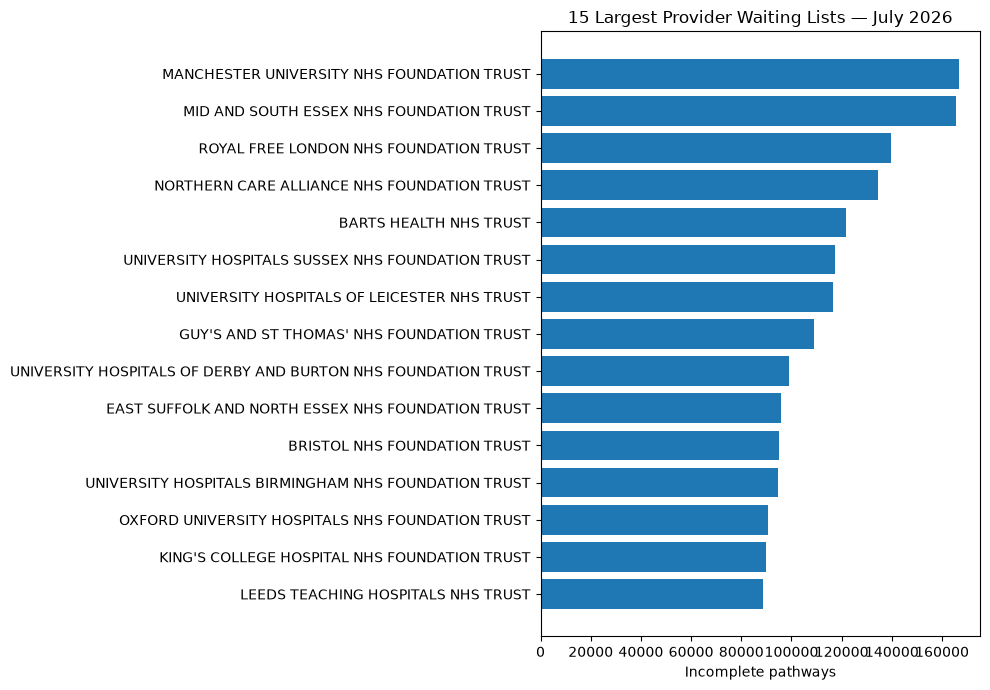

In [16]:
plot_data = largest_waiting_lists.sort_values("total_waiting")

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    plot_data["provider_name"],
    plot_data["total_waiting"]
)

ax.set_title(f"15 Largest Provider Waiting Lists — {latest_month:%B %Y}")
ax.set_xlabel("Incomplete pathways")
ax.set_ylabel("")

plt.tight_layout()
plt.show()


A large waiting list does not automatically mean poor performance. Provider size, service mix and referral volumes differ, so volume should be considered alongside waiting-time measures.


## Lowest 18-week performance among providers with 1,000+ pathways

In [17]:
lowest_18_performance = (
    latest_providers[
        latest_providers["total_waiting"] >= 1000
    ][
        [
            "provider_code",
            "provider_name",
            "total_waiting",
            "pct_within_18_weeks",
            "over_18_weeks",
            "over_52_weeks",
            "median_wait_weeks",
            "p92_wait_weeks"
        ]
    ]
    .sort_values("pct_within_18_weeks")
    .head(15)
)

lowest_18_performance


,provider_code,provider_name,total_waiting,pct_within_18_weeks,over_18_weeks,over_52_weeks,median_wait_weeks,p92_wait_weeks
2332,RAJ,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,165372,49.77,83061,13102,18.10,51.88
2302,RYR,UNIVERSITY HOSPITALS SUSSEX NHS FOUNDATION TRUST,117207,53.08,54990,5120,16.24,46.62
2296,RVV,EAST KENT HOSPITALS UNIVERSITY NHS FOUNDATION ...,83070,55.21,37210,2648,15.48,43.40
2360,RM3,NORTHERN CARE ALLIANCE NHS FOUNDATION TRUST,134418,55.87,59316,3774,14.99,42.92
2388,RWA,HULL UNIVERSITY TEACHING HOSPITALS NHS TRUST,85756,56.01,37724,3331,14.93,44.75
2368,RXL,BLACKPOOL TEACHING HOSPITALS NHS FOUNDATION TRUST,40789,57.84,17195,1122,14.35,41.61
2279,RN3,GREAT WESTERN HOSPITALS NHS FOUNDATION TRUST,42801,57.88,18027,1080,14.30,41.82
2291,RPA,MEDWAY NHS FOUNDATION TRUST,35225,58.00,14794,727,14.65,39.47
2311,RKB,UNIVERSITY HOSPITALS COVENTRY AND WARWICKSHIRE...,68578,58.29,28603,2567,14.30,44.87
2284,RDR,SUSSEX COMMUNITY NHS FOUNDATION TRUST,13533,58.34,5638,419,14.50,42.79


The 1,000-pathway threshold is only a display filter to reduce misleading comparisons with very small denominators; it is not an NHS performance threshold.


## Providers with the most 52+ week waits

In [18]:
highest_52_week_waits = (
    latest_providers[
        [
            "provider_code",
            "provider_name",
            "total_waiting",
            "over_52_weeks",
            "pct_over_52_weeks",
            "pct_within_18_weeks"
        ]
    ]
    .sort_values(["over_52_weeks", "total_waiting"], ascending=[False, False])
    .head(15)
)

highest_52_week_waits


,provider_code,provider_name,total_waiting,over_52_weeks,pct_over_52_weeks,pct_within_18_weeks
2332,RAJ,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,165372,13102,7.92,49.77
2302,RYR,UNIVERSITY HOSPITALS SUSSEX NHS FOUNDATION TRUST,117207,5120,4.37,53.08
2360,RM3,NORTHERN CARE ALLIANCE NHS FOUNDATION TRUST,134418,3774,2.81,55.87
2388,RWA,HULL UNIVERSITY TEACHING HOSPITALS NHS TRUST,85756,3331,3.88,56.01
2296,RVV,EAST KENT HOSPITALS UNIVERSITY NHS FOUNDATION ...,83070,2648,3.19,55.21
2311,RKB,UNIVERSITY HOSPITALS COVENTRY AND WARWICKSHIRE...,68578,2567,3.74,58.29
2326,RWE,UNIVERSITY HOSPITALS OF LEICESTER NHS TRUST,116532,2407,2.07,60.00
2287,RHU,PORTSMOUTH HOSPITALS UNIVERSITY NHS TRUST,58044,2044,3.52,61.03
2324,RTG,UNIVERSITY HOSPITALS OF DERBY AND BURTON NHS F...,99108,2039,2.06,60.72
2328,RX1,NOTTINGHAM UNIVERSITY HOSPITALS NHS TRUST,78304,1899,2.43,61.51


# Part E — Provider change over time

## Compare first and latest available records

In [19]:
provider_sorted = provider_df.sort_values(
    ["provider_code", "reporting_month"]
)

provider_first = provider_sorted.groupby("provider_code", as_index=False).first()
provider_last = provider_sorted.groupby("provider_code", as_index=False).last()

provider_change = provider_first[
    [
        "provider_code",
        "provider_name",
        "reporting_month",
        "total_waiting",
        "pct_within_18_weeks",
        "over_52_weeks"
    ]
].merge(
    provider_last[
        [
            "provider_code",
            "provider_name",
            "reporting_month",
            "total_waiting",
            "pct_within_18_weeks",
            "over_52_weeks"
        ]
    ],
    on="provider_code",
    suffixes=("_first", "_latest")
)

months_observed = (
    provider_sorted
    .groupby("provider_code")["reporting_month"]
    .nunique()
)

provider_change["months_observed"] = (
    provider_change["provider_code"].map(months_observed)
)

provider_change["waiting_change"] = (
    provider_change["total_waiting_latest"]
    - provider_change["total_waiting_first"]
)

provider_change["waiting_change_pct"] = np.where(
    provider_change["total_waiting_first"] != 0,
    provider_change["waiting_change"]
    / provider_change["total_waiting_first"] * 100,
    np.nan
)

provider_change["within_18_change_pp"] = (
    provider_change["pct_within_18_weeks_latest"]
    - provider_change["pct_within_18_weeks_first"]
)

provider_change["over_52_change"] = (
    provider_change["over_52_weeks_latest"]
    - provider_change["over_52_weeks_first"]
)

provider_change.head()


/var/folders/zd/0bzshzyx5tx0n2wd8q88c7480000gn/T/ipykernel_8732/4257814024.py:5: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  provider_first = provider_sorted.groupby("provider_code", as_index=False).first()
/var/folders/zd/0bzshzyx5tx0n2wd8q88c7480000gn/T/ipykernel_8732/4257814024.py:6: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  provider_last = provider_sorted.groupby("provider_code", as_index=False).last()


,provider_code,provider_name_first,reporting_month_first,total_waiting_first,pct_within_18_weeks_first,over_52_weeks_first,provider_name_latest,reporting_month_latest,total_waiting_latest,pct_within_18_weeks_latest,over_52_weeks_latest,months_observed,waiting_change,waiting_change_pct,within_18_change_pp,over_52_change
0,R0A,MANCHESTER UNIVERSITY NHS FOUNDATION TRUST,2025-04-01,192230,51.04,8404,MANCHESTER UNIVERSITY NHS FOUNDATION TRUST,2026-07-01,166776,63.88,1385,16,-25454,-13.24,12.84,-7019
1,R0B,SOUTH TYNESIDE AND SUNDERLAND NHS FOUNDATION T...,2025-04-01,57403,74.99,25,SOUTH TYNESIDE AND SUNDERLAND NHS FOUNDATION T...,2026-07-01,61863,75.82,1,16,4460,7.77,0.83,-24
2,R0D,UNIVERSITY HOSPITALS DORSET NHS FOUNDATION TRUST,2025-04-01,64457,60.80,2261,UNIVERSITY HOSPITALS DORSET NHS FOUNDATION TRUST,2026-07-01,67345,66.77,773,16,2888,4.48,5.97,-1488
3,R1A,HEREFORDSHIRE AND WORCESTERSHIRE HEALTH AND CA...,2025-04-01,96,96.88,0,HEREFORDSHIRE AND WORCESTERSHIRE HEALTH AND CA...,2026-07-01,33,96.97,0,16,-63,-65.62,0.09,0
4,R1D,SHROPSHIRE COMMUNITY HEALTH NHS TRUST,2025-04-01,9351,58.18,280,SHROPSHIRE COMMUNITY HEALTH NHS TRUST,2026-07-01,8036,81.57,0,16,-1315,-14.06,23.39,-280


In [20]:
continuous_providers = provider_change[
    provider_change["months_observed"] == 16
].copy()

print("Providers observed in all 16 months:", len(continuous_providers))


Providers observed in all 16 months: 145


## Biggest improvements in 18-week performance

In [21]:
most_improved_18 = (
    continuous_providers[
        [
            "provider_code",
            "provider_name_latest",
            "pct_within_18_weeks_first",
            "pct_within_18_weeks_latest",
            "within_18_change_pp",
            "total_waiting_latest"
        ]
    ]
    .sort_values("within_18_change_pp", ascending=False)
    .head(15)
)

most_improved_18


,provider_code,provider_name_latest,pct_within_18_weeks_first,pct_within_18_weeks_latest,within_18_change_pp,total_waiting_latest
93,RPG,OXLEAS NHS FOUNDATION TRUST,54.16,100.00,45.84,200
4,R1D,SHROPSHIRE COMMUNITY HEALTH NHS TRUST,58.18,81.57,23.39,8036
65,RJR,COUNTESS OF CHESTER HOSPITAL NHS FOUNDATION TRUST,47.07,67.81,20.74,29228
97,RQW,THE PRINCESS ALEXANDRA HOSPITAL NHS TRUST,48.78,68.47,19.69,38992
71,RL1,THE ROBERT JONES AND AGNES HUNT ORTHOPAEDIC HO...,44.92,64.59,19.67,13280
145,RXW,THE SHREWSBURY AND TELFORD HOSPITAL NHS TRUST,49.61,67.95,18.34,37291
104,RRK,UNIVERSITY HOSPITALS BIRMINGHAM NHS FOUNDATION...,49.72,67.23,17.51,94561
149,RYW,BIRMINGHAM COMMUNITY HEALTHCARE NHS FOUNDATION...,65.84,81.93,16.09,15246
45,RGM,ROYAL PAPWORTH HOSPITAL NHS FOUNDATION TRUST,64.51,80.49,15.98,5921
144,RXR,EAST LANCASHIRE HOSPITALS NHS TRUST,56.46,72.07,15.61,47026


## Largest deterioration in 18-week performance

In [22]:
largest_deterioration_18 = (
    continuous_providers[
        [
            "provider_code",
            "provider_name_latest",
            "pct_within_18_weeks_first",
            "pct_within_18_weeks_latest",
            "within_18_change_pp",
            "total_waiting_latest"
        ]
    ]
    .sort_values("within_18_change_pp")
    .head(15)
)

largest_deterioration_18


,provider_code,provider_name_latest,pct_within_18_weeks_first,pct_within_18_weeks_latest,within_18_change_pp,total_waiting_latest
106,RT1,CAMBRIDGESHIRE AND PETERBOROUGH NHS FOUNDATION...,52.21,32.89,-19.32,76
34,RDR,SUSSEX COMMUNITY NHS FOUNDATION TRUST,72.78,58.34,-14.44,13533
122,RW5,LANCASHIRE & SOUTH CUMBRIA NHS FOUNDATION TRUST,97.57,83.88,-13.69,4634
151,TAD,BRADFORD DISTRICT CARE NHS FOUNDATION TRUST,69.45,58.38,-11.07,591
120,RW1,HAMPSHIRE AND ISLE OF WIGHT HEALTHCARE NHS FOU...,92.78,85.31,-7.47,4437
101,RRE,MIDLANDS PARTNERSHIP UNIVERSITY NHS FOUNDATION...,96.65,92.03,-4.62,10360
119,RVW,NORTH TEES AND HARTLEPOOL NHS FOUNDATION TRUST,73.83,71.18,-2.65,23667
142,RXP,COUNTY DURHAM AND DARLINGTON NHS FOUNDATION TRUST,67.83,65.35,-2.48,54384
60,RJ8,CORNWALL PARTNERSHIP NHS FOUNDATION TRUST,98.03,96.56,-1.47,756
85,RNS,NORTHAMPTON GENERAL HOSPITAL NHS TRUST,62.01,60.57,-1.44,39936


# Part F — Treatment-function analysis

## Exclude provider totals

In [23]:
specialty_df = full_df[
    full_df["row_type"] == "treatment_function"
].copy()

print("Treatment-function rows:", len(specialty_df))


Treatment-function rows: 55085


## Aggregate specialties nationally by month

In [24]:
specialty_monthly = (
    specialty_df
    .groupby(
        [
            "reporting_month",
            "reporting_period",
            "treatment_function_code",
            "treatment_function"
        ],
        as_index=False
    )
    .agg(
        total_waiting=("total_waiting", "sum"),
        within_18_weeks=("within_18_weeks", "sum"),
        over_18_weeks=("over_18_weeks", "sum"),
        over_52_weeks=("over_52_weeks", "sum"),
        over_65_weeks=("over_65_weeks", "sum"),
        over_78_weeks=("over_78_weeks", "sum"),
    )
)

specialty_monthly["pct_within_18_weeks"] = (
    specialty_monthly["within_18_weeks"]
    / specialty_monthly["total_waiting"]
    * 100
)

specialty_monthly.head()


,reporting_month,reporting_period,treatment_function_code,treatment_function,total_waiting,within_18_weeks,over_18_weeks,over_52_weeks,over_65_weeks,over_78_weeks,pct_within_18_weeks
0,2025-04-01,2025-04,C_100,General Surgery Service,362385,208646,153739,11334,411,33,57.58
1,2025-04-01,2025-04,C_101,Urology Service,392509,229995,162514,11730,415,24,58.60
2,2025-04-01,2025-04,C_110,Trauma and Orthopaedic Service,705022,379717,325305,23274,1495,154,53.86
3,2025-04-01,2025-04,C_120,Ear Nose and Throat Service,614666,306522,308144,26543,1255,108,49.87
4,2025-04-01,2025-04,C_130,Ophthalmology Service,535569,355259,180310,9003,439,54,66.33


## Largest specialty waiting lists in the latest month

In [25]:
latest_specialties = specialty_monthly[
    specialty_monthly["reporting_month"] == latest_month
].copy()

top_specialties = (
    latest_specialties[
        [
            "treatment_function_code",
            "treatment_function",
            "total_waiting",
            "pct_within_18_weeks",
            "over_52_weeks",
            "over_65_weeks",
            "over_78_weeks"
        ]
    ]
    .sort_values("total_waiting", ascending=False)
    .head(15)
)

top_specialties


,treatment_function_code,treatment_function,total_waiting,pct_within_18_weeks,over_52_weeks,over_65_weeks,over_78_weeks
347,C_110,Trauma and Orthopaedic Service,690577,59.05,18709,1974,353
363,X02,Other - Medical Services,598519,70.50,4806,242,81
362,C_502,Gynaecology Service,564353,59.82,11755,682,59
348,C_120,Ear Nose and Throat Service,561209,57.16,12251,940,112
349,C_130,Ophthalmology Service,526190,70.32,4678,163,13
366,X05,Other - Surgical Services,462553,66.23,7555,571,64
357,C_330,Dermatology Service,383179,67.90,4641,98,5
356,C_320,Cardiology Service,362934,67.75,2925,303,23
346,C_101,Urology Service,353625,64.36,4937,536,102
345,C_100,General Surgery Service,349598,61.80,7938,589,84


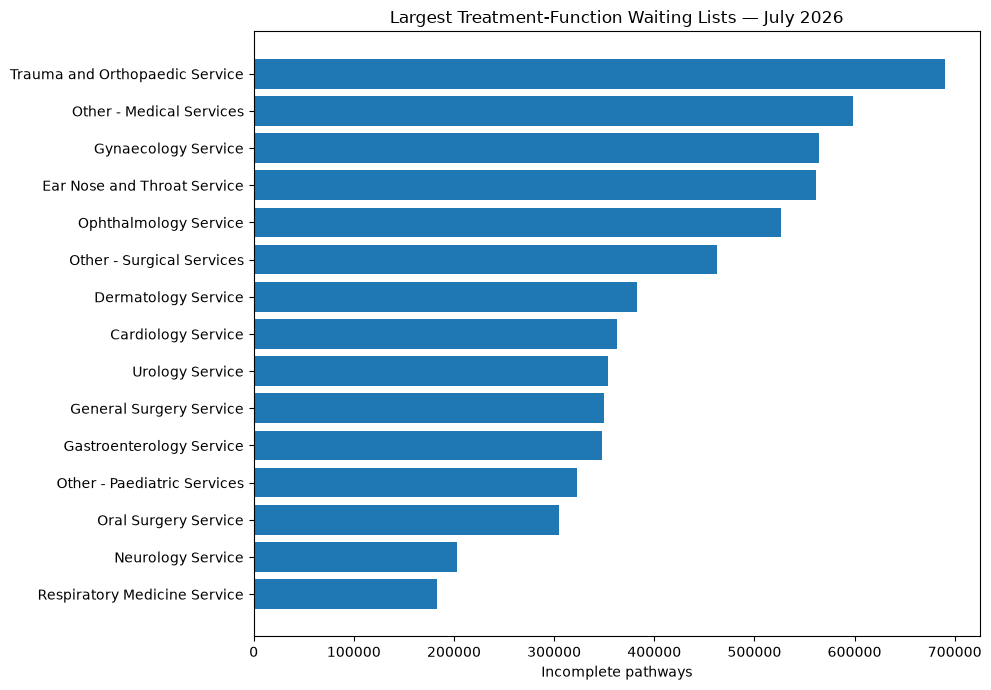

In [26]:
plot_data = top_specialties.sort_values("total_waiting")

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    plot_data["treatment_function"],
    plot_data["total_waiting"]
)

ax.set_title(f"Largest Treatment-Function Waiting Lists — {latest_month:%B %Y}")
ax.set_xlabel("Incomplete pathways")
ax.set_ylabel("")

plt.tight_layout()
plt.show()


## Specialties with the greatest 52+ week pressure

In [27]:
specialty_long_waits = (
    latest_specialties[
        [
            "treatment_function_code",
            "treatment_function",
            "total_waiting",
            "over_52_weeks",
            "pct_within_18_weeks"
        ]
    ]
    .sort_values("over_52_weeks", ascending=False)
    .head(15)
)

specialty_long_waits


,treatment_function_code,treatment_function,total_waiting,over_52_weeks,pct_within_18_weeks
347,C_110,Trauma and Orthopaedic Service,690577,18709,59.05
348,C_120,Ear Nose and Throat Service,561209,12251,57.16
362,C_502,Gynaecology Service,564353,11755,59.82
345,C_100,General Surgery Service,349598,7938,61.80
350,C_140,Oral Surgery Service,305208,7679,53.94
366,X05,Other - Surgical Services,462553,7555,66.23
346,C_101,Urology Service,353625,4937,64.36
363,X02,Other - Medical Services,598519,4806,70.50
349,C_130,Ophthalmology Service,526190,4678,70.32
357,C_330,Dermatology Service,383179,4641,67.90


## Specialty change from first to latest month

In [28]:
first_month = specialty_monthly["reporting_month"].min()
last_month = specialty_monthly["reporting_month"].max()

specialty_first = specialty_monthly[
    specialty_monthly["reporting_month"] == first_month
][
    [
        "treatment_function_code",
        "treatment_function",
        "total_waiting",
        "pct_within_18_weeks",
        "over_52_weeks"
    ]
]

specialty_last = specialty_monthly[
    specialty_monthly["reporting_month"] == last_month
][
    [
        "treatment_function_code",
        "treatment_function",
        "total_waiting",
        "pct_within_18_weeks",
        "over_52_weeks"
    ]
]

specialty_change = specialty_first.merge(
    specialty_last,
    on="treatment_function_code",
    suffixes=("_first", "_latest")
)

specialty_change["waiting_change"] = (
    specialty_change["total_waiting_latest"]
    - specialty_change["total_waiting_first"]
)

specialty_change["waiting_change_pct"] = np.where(
    specialty_change["total_waiting_first"] != 0,
    specialty_change["waiting_change"]
    / specialty_change["total_waiting_first"] * 100,
    np.nan
)

specialty_change["within_18_change_pp"] = (
    specialty_change["pct_within_18_weeks_latest"]
    - specialty_change["pct_within_18_weeks_first"]
)

specialty_change["over_52_change"] = (
    specialty_change["over_52_weeks_latest"]
    - specialty_change["over_52_weeks_first"]
)

specialty_change.sort_values("waiting_change", ascending=False)


,treatment_function_code,treatment_function_first,total_waiting_first,pct_within_18_weeks_first,over_52_weeks_first,treatment_function_latest,total_waiting_latest,pct_within_18_weeks_latest,over_52_weeks_latest,waiting_change,waiting_change_pct,within_18_change_pp,over_52_change
12,C_330,Dermatology Service,371552,58.51,9139,Dermatology Service,383179,67.90,4641,11627,3.13,9.39,-4498
17,C_502,Gynaecology Service,555645,54.75,17738,Gynaecology Service,564353,59.82,11755,8708,1.57,5.07,-5983
7,C_160,Plastic Surgery Service,97999,53.35,3519,Plastic Surgery Service,103678,59.01,3197,5679,5.79,5.66,-322
16,C_430,Elderly Medicine Service,23533,81.69,48,Elderly Medicine Service,26741,83.75,79,3208,13.63,2.06,31
19,X03,Other - Mental Health Services,2493,73.69,5,Other - Mental Health Services,3445,80.44,2,952,38.19,6.75,-3
8,C_170,Cardiothoracic Surgery Service,9872,66.79,174,Cardiothoracic Surgery Service,8577,73.73,130,-1295,-13.12,6.94,-44
9,C_300,General Internal Medicine Service,37550,68.13,278,General Internal Medicine Service,32322,73.40,163,-5228,-13.92,5.27,-115
6,C_150,Neurosurgical Service,54491,57.36,1380,Neurosurgical Service,49130,62.02,768,-5361,-9.84,4.66,-612
15,C_410,Rheumatology Service,122249,66.14,1616,Rheumatology Service,116705,70.12,1224,-5544,-4.54,3.97,-392
20,X04,Other - Paediatric Services,331427,61.21,8509,Other - Paediatric Services,323196,67.07,3977,-8231,-2.48,5.86,-4532


# Part G — Gloucestershire Hospitals case study

## Provider-level trend

In [29]:
glos = (
    provider_df[
        provider_df["provider_code"] == "RTE"
    ]
    .sort_values("reporting_month")
    .copy()
)

glos[
    [
        "reporting_period",
        "provider_name",
        "total_waiting",
        "pct_within_18_weeks",
        "median_wait_weeks",
        "p92_wait_weeks",
        "over_52_weeks",
        "over_65_weeks",
        "over_78_weeks"
    ]
]


,reporting_period,provider_name,total_waiting,pct_within_18_weeks,median_wait_weeks,p92_wait_weeks,over_52_weeks,over_65_weeks,over_78_weeks
34,2025-04,GLOUCESTERSHIRE HOSPITALS NHS FOUNDATION TRUST,66826,69.00,9.90,34.30,93,3,1
186,2025-05,GLOUCESTERSHIRE HOSPITALS NHS FOUNDATION TRUST,62970,68.61,10.28,34.81,75,3,0
338,2025-06,GLOUCESTERSHIRE HOSPITALS NHS FOUNDATION TRUST,60281,68.89,10.03,34.58,46,2,1
490,2025-07,GLOUCESTERSHIRE HOSPITALS NHS FOUNDATION TRUST,59146,67.91,10.49,35.06,39,3,1
640,2025-08,GLOUCESTERSHIRE HOSPITALS NHS FOUNDATION TRUST,59797,67.25,10.74,34.75,36,2,2
790,2025-09,GLOUCESTERSHIRE HOSPITALS NHS FOUNDATION TRUST,63422,69.76,10.43,33.79,35,1,0
940,2025-10,GLOUCESTERSHIRE HOSPITALS NHS FOUNDATION TRUST,62288,69.38,9.87,34.22,28,0,0
1089,2025-11,GLOUCESTERSHIRE HOSPITALS NHS FOUNDATION TRUST,63147,70.00,9.96,34.00,31,0,0
1239,2025-12,GLOUCESTERSHIRE HOSPITALS NHS FOUNDATION TRUST,62157,69.27,10.16,34.35,30,0,0
1389,2026-01,GLOUCESTERSHIRE HOSPITALS NHS FOUNDATION TRUST,62862,68.51,10.38,34.32,21,1,0


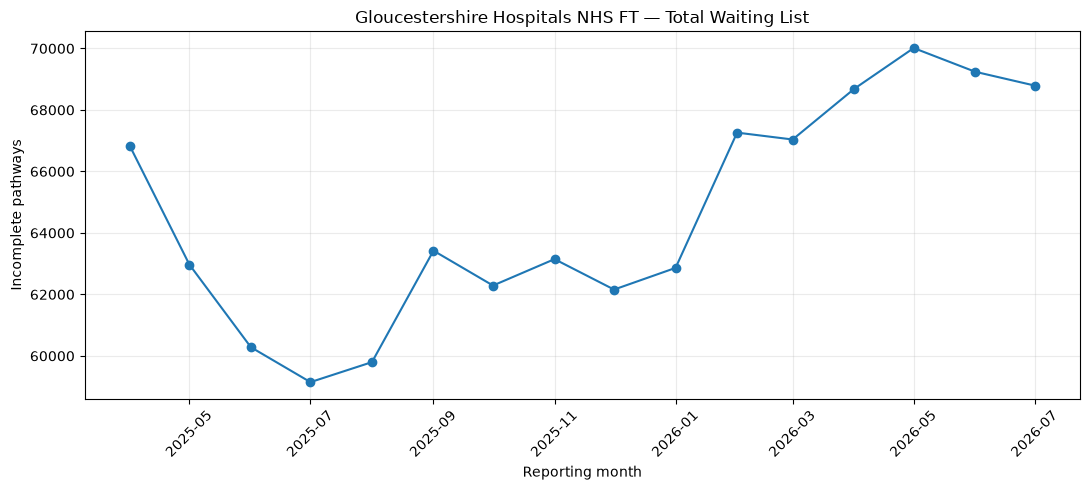

In [30]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    glos["reporting_month"],
    glos["total_waiting"],
    marker="o"
)

ax.set_title("Gloucestershire Hospitals NHS FT — Total Waiting List")
ax.set_xlabel("Reporting month")
ax.set_ylabel("Incomplete pathways")
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()


## Gloucestershire vs overall 18-week performance

In [31]:
glos_vs_overall = glos[
    [
        "reporting_month",
        "reporting_period",
        "pct_within_18_weeks"
    ]
].merge(
    national_monthly[
        [
            "reporting_month",
            "pct_within_18_weeks"
        ]
    ],
    on="reporting_month",
    suffixes=("_glos", "_overall")
)

glos_vs_overall["difference_pp"] = (
    glos_vs_overall["pct_within_18_weeks_glos"]
    - glos_vs_overall["pct_within_18_weeks_overall"]
)

glos_vs_overall


,reporting_month,reporting_period,pct_within_18_weeks_glos,pct_within_18_weeks_overall,difference_pp
0,2025-04-01,2025-04,69.00,58.75,10.25
1,2025-05-01,2025-05,68.61,59.94,8.67
2,2025-06-01,2025-06,68.89,60.57,8.32
3,2025-07-01,2025-07,67.91,60.27,7.64
4,2025-08-01,2025-08,67.25,59.91,7.34
5,2025-09-01,2025-09,69.76,60.73,9.03
6,2025-10-01,2025-10,69.38,60.71,8.67
7,2025-11-01,2025-11,70.00,60.63,9.37
8,2025-12-01,2025-12,69.27,60.50,8.77
9,2026-01-01,2026-01,68.51,60.58,7.93


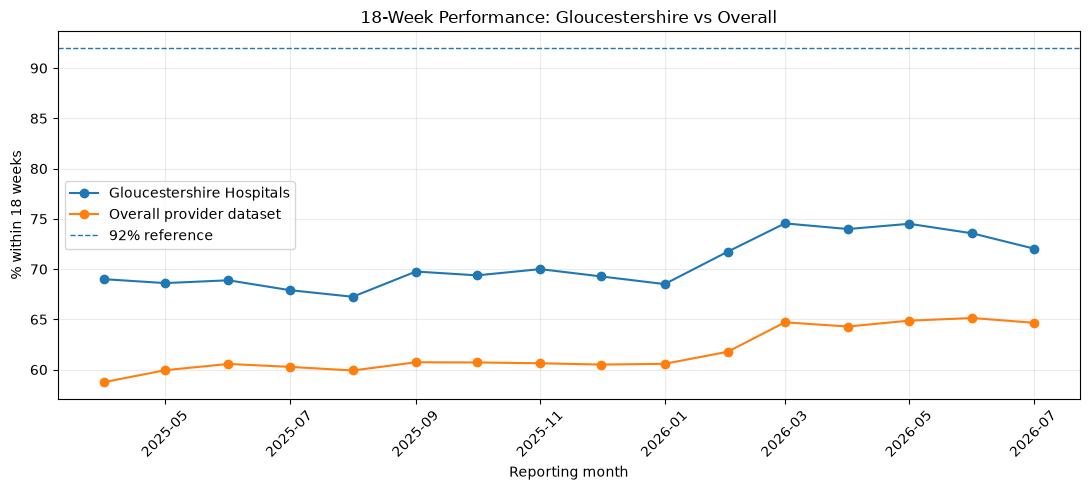

In [32]:
fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    glos_vs_overall["reporting_month"],
    glos_vs_overall["pct_within_18_weeks_glos"],
    marker="o",
    label="Gloucestershire Hospitals"
)

ax.plot(
    glos_vs_overall["reporting_month"],
    glos_vs_overall["pct_within_18_weeks_overall"],
    marker="o",
    label="Overall provider dataset"
)

ax.axhline(92, linestyle="--", linewidth=1, label="92% reference")

ax.set_title("18-Week Performance: Gloucestershire vs Overall")
ax.set_xlabel("Reporting month")
ax.set_ylabel("% within 18 weeks")
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


## Gloucestershire specialties in the latest month

In [33]:
glos_specialties_latest = (
    specialty_df[
        (specialty_df["provider_code"] == "RTE")
        & (specialty_df["reporting_month"] == latest_month)
    ][
        [
            "treatment_function_code",
            "treatment_function",
            "total_waiting",
            "pct_within_18_weeks",
            "median_wait_weeks",
            "p92_wait_weeks",
            "over_52_weeks",
            "over_65_weeks",
            "over_78_weeks"
        ]
    ]
    .sort_values("total_waiting", ascending=False)
)

glos_specialties_latest


,treatment_function_code,treatment_function,total_waiting,pct_within_18_weeks,median_wait_weeks,p92_wait_weeks,over_52_weeks,over_65_weeks,over_78_weeks
54746,C_110,Trauma and Orthopaedic Service,9512,53.27,16.27,41.87,19,0,0
54762,X02,Other - Medical Services,8638,82.57,7.42,27.06,1,0,0
54755,C_320,Cardiology Service,6595,75.56,11.29,29.86,0,0,0
54765,X05,Other - Surgical Services,6498,76.22,9.29,33.15,2,0,0
54747,C_120,Ear Nose and Throat Service,5718,57.85,14.84,34.90,0,0,0
54756,C_330,Dermatology Service,5401,70.06,10.73,35.95,0,0,0
54754,C_301,Gastroenterology Service,4671,86.49,8.16,23.12,0,0,0
54761,C_502,Gynaecology Service,4524,65.58,12.19,35.54,1,0,0
54749,C_140,Oral Surgery Service,3595,61.53,14.01,32.84,0,0,0
54745,C_101,Urology Service,3511,77.27,9.64,31.32,0,0,0


## Gloucestershire specialties with the lowest 18-week performance

In [34]:
glos_pressure_specialties = (
    glos_specialties_latest[
        glos_specialties_latest["total_waiting"] > 0
    ]
    .sort_values(
        ["pct_within_18_weeks", "total_waiting"],
        ascending=[True, False]
    )
)

glos_pressure_specialties.head(10)


,treatment_function_code,treatment_function,total_waiting,pct_within_18_weeks,median_wait_weeks,p92_wait_weeks,over_52_weeks,over_65_weeks,over_78_weeks
54744,C_100,General Surgery Service,2,50.00,NaN,NaN,0,0,0
54746,C_110,Trauma and Orthopaedic Service,9512,53.27,16.27,41.87,19,0,0
54747,C_120,Ear Nose and Throat Service,5718,57.85,14.84,34.90,0,0,0
54749,C_140,Oral Surgery Service,3595,61.53,14.01,32.84,0,0,0
54761,C_502,Gynaecology Service,4524,65.58,12.19,35.54,1,0,0
54759,C_410,Rheumatology Service,1234,68.56,10.57,35.92,1,0,0
54756,C_330,Dermatology Service,5401,70.06,10.73,35.95,0,0,0
54764,X04,Other - Paediatric Services,1268,71.61,11.06,29.66,0,0,0
54755,C_320,Cardiology Service,6595,75.56,11.29,29.86,0,0,0
54765,X05,Other - Surgical Services,6498,76.22,9.29,33.15,2,0,0


# Part H — Portfolio-ready summary

## Generate headline findings

In [35]:
start_row = national_monthly.iloc[0]
end_row = national_monthly.iloc[-1]

wait_abs = end_row["total_waiting"] - start_row["total_waiting"]
wait_pct = wait_abs / start_row["total_waiting"] * 100

performance_pp = (
    end_row["pct_within_18_weeks"]
    - start_row["pct_within_18_weeks"]
)

largest_specialty = latest_specialties.sort_values(
    "total_waiting",
    ascending=False
).iloc[0]

highest_52_specialty = latest_specialties.sort_values(
    "over_52_weeks",
    ascending=False
).iloc[0]

print("HEADLINE FINDINGS")
print("-----------------")
print(
    f"1. Total incomplete pathways changed from "
    f"{start_row['total_waiting']:,.0f} in {start_row['reporting_period']} "
    f"to {end_row['total_waiting']:,.0f} in {end_row['reporting_period']}: "
    f"{wait_abs:+,.0f} ({wait_pct:+.2f}%)."
)

print(
    f"2. Weighted 18-week performance changed from "
    f"{start_row['pct_within_18_weeks']:.2f}% to "
    f"{end_row['pct_within_18_weeks']:.2f}%: "
    f"{performance_pp:+.2f} percentage points."
)

print(
    f"3. In the latest month, {largest_specialty['treatment_function']} "
    f"had the largest specialty waiting list at "
    f"{largest_specialty['total_waiting']:,.0f} pathways."
)

print(
    f"4. In the latest month, {highest_52_specialty['treatment_function']} "
    f"had the highest 52+ week count at "
    f"{highest_52_specialty['over_52_weeks']:,.0f}."
)

if not glos.empty:
    glos_start = glos.iloc[0]
    glos_end = glos.iloc[-1]

    glos_wait_change = (
        glos_end["total_waiting"]
        - glos_start["total_waiting"]
    )

    glos_perf_change = (
        glos_end["pct_within_18_weeks"]
        - glos_start["pct_within_18_weeks"]
    )

    print(
        f"5. Gloucestershire Hospitals' waiting list changed by "
        f"{glos_wait_change:+,.0f} pathways, while 18-week performance "
        f"moved by {glos_perf_change:+.2f} percentage points."
    )


HEADLINE FINDINGS
-----------------
1. Total incomplete pathways changed from 6,998,951 in 2025-04 to 6,687,433 in 2026-07: -311,518 (-4.45%).
2. Weighted 18-week performance changed from 58.75% to 64.66%: +5.91 percentage points.
3. In the latest month, Trauma and Orthopaedic Service had the largest specialty waiting list at 690,577 pathways.
4. In the latest month, Trauma and Orthopaedic Service had the highest 52+ week count at 18,709.
5. Gloucestershire Hospitals' waiting list changed by +1,966 pathways, while 18-week performance moved by +3.05 percentage points.


# Analytical cautions

- The dataset contains **pathways**, not unique individual patients.
- Overall percentages should be weighted by pathway counts rather than calculated as simple averages of provider percentages.
- Provider coverage may change across months.
- Large waiting lists can partly reflect provider size and service mix.
- The analysis is descriptive and does not establish why performance changed.
- `C_999` provider totals must not be added to individual treatment-function rows.
- Missing waiting-time statistics should remain missing rather than being replaced with zero.


# EDA completion checklist

By the end of this notebook, you should have:

- quantified the total waiting-list trend;
- calculated month-on-month changes;
- tracked weighted 18-week performance;
- analysed 52+, 65+ and 78+ week waits;
- ranked high-pressure providers;
- identified improving and deteriorating providers;
- analysed specialty-level pressure;
- examined Gloucestershire Hospitals over time; and
- generated evidence-based headline findings.

## Next stage

The recommended next step is the **SQL stage**:

`05_sql_analysis.sql`

There we will load the clean trend dataset into MySQL and recreate the major business questions using SQL before building the Power BI dashboard.
